# Perceptron

The perceptron is a supervised machine learning algorithm for binary classification. Binary classification is the simplest form of classification where sample data belongs to only one of two classes. This notebook explores the performance and complexity of the perceptron starting with simple binary representations, then expanding to classifying hnadwritten numbers.

## Perceptron Learning Algorithm

The perceptron learning algorithm is a simple and surprisingly powerful model for binary classification. The perceptron takes a linear combination of features and weights. Weights are then updated based on the traning classification. 

Formally, the training data $D$ is defined as $D = \{(X_1,y_1),(X_2,y_2), \dots, (X_n,y_n)\}$ where $X_i$ is the $i^{th}$ feature vector and $y_i$ is the labeled feature vector class where $y_i \in \{0,1\}$. $X_i \in \mathbb{R}^N$ where $N$ is the size of the feature vector. Additionaly, $X_{i,0}=1$ for $i=1,\dots,N$. $X_0$ and $w_0$ represent the bias term, independent from the input feature values.

Initially, the weights are set to zero and the weight vector is defined as $w = (w_0, w_1, \dots, w_N)$. Given an initial number of training steps $S$, the perceptron makes training predictions on each step $t$ and for each feature $i$ for $i=1,\dots,N$.
$$
y_i(t) = w_0(t)X_{i,0} + w_1(t)X_{i,1} + \dots + w_N(t)X_{i,N}
$$
The weights are then updated for the next training step $t+1$.
$$
w_i(t+1) = w_i(t) + l_i * X_i
$$
where is the prediction sign adjustment for the training prediction and defined as
$$
l_i = \begin{cases}
1 & \text{if } y_i \le 0 \text{ and } y_i(t) > 0 \\
-1 & \text{if } y_i > 0 \text { and } y_i(t) \le 0 \\
0 & \text{if } y_i = y_i(t)
\end{cases}
$$
$y_i$ is the true class for the feature vector $X_i$ whereas $y_i(t)$ is the predicted feature class. This process is conducted for $S$ repetitions or there is a convergance of weights.

### Section 1: Simple Binary Representations

To understand the performance and limitations of the perceptron, lets start with the simplest sample space: the set of all two digit binary numbers. The sample space is $\Omega = \{(0,0),(0,1),(1,0),(1,1)\}$. The question is what can the perceptron learn to classify? To answer this, we need to understand the concept of *linear seperability*. The perceptron can achive a 100% accuracy in classifying sample features only if there exists a hyperplane that seperates the class labels. The hyperplane defines what the perceptron can and cannot learn.

#### Linear Seperability
Let $X \subset \mathbb{R}^d$ be a set of $m$ points and $Y \subset \mathbb{R}^d$ be a set of $n$ points in $d-dimensional$ Euclidean space. $X$ and $Y$ are linearly seperable if there exists a normal vector $w$ and a scalar offset $k$ such that either every point $x \in X$ satisfies $w^Tx+k > 0$ and every point $y \in Y$ satisfies $w^Ty+k < 0$ or every point $x \in X$ satisfies $w^Tx+k < 0$ and every point $y \in Y$ satisfies $w^Ty+k > 0$.

In the simple binary example, this means there must be a line that cleanly splits the two classes that we want to learn. The section below illustrates the hyperplanes for the simple example.

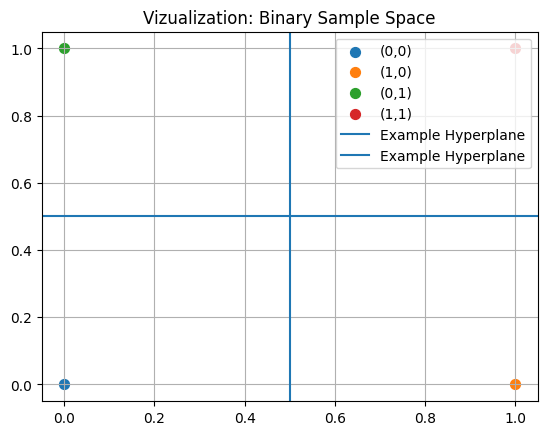

In [18]:
import matplotlib.pyplot as plt
import numpy as np

sample_space = [(0,0),(1,0),(0,1),(1,1)]

for point in sample_space:
    plt.scatter(point[0], point[1], s=50, label=f"({point[0]},{point[1]})")

# Plot examples of hyperplanes
plt.axvline(x=0.5, label="Example Hyperplane")
plt.axhline(y=0.5, label="Example Hyperplane")

plt.title("Vizualization: Binary Sample Space")
plt.legend()
plt.grid()
plt.show()

Note that there are more hyperplanes (such as diagonally to seperate 3 points). With this in mind, we can now define what the perceptron can and cannot learn in our example. Lets have our perceptron learn the $OR$ operation. This means that if there exists a $1$ in the input, it belongs to class $1$. Otherwise, it belongs to class $0$. 

First, are these points linearly seperable? Visually, yes. But for concreteness, lets see if the perceptron can be trained to classify the correct $OR$ operations.

In [19]:
# Create the class labels for the OR operation
labels = [0, 1, 1, 1]

features = np.array(sample_space)
features = np.insert(features, obj=0, values=1, axis=1) # For bias

labels = np.array(labels)

# Initialize the weights
weights = np.zeros(shape=len(features[0]))

S = 10   # Number of training steps

converged = False
converged_steps = 0
converged_weights = [weights]

for t in range(S):
    # Cycle through the training observations
    idx = t % len(features)
    X_train = features[idx]
    y_train = labels[idx]

    y_hat = np.dot(X_train, weights)

    l = 0
    if y_hat < 0 and y_train == 1:
        l = 1
    elif  y_hat >= 0 and y_train == 0:
        l = -1
    weights = weights + l * X_train

    if np.array_equal(weights, converged_weights[-1]) and not converged:
        converged_steps = t + 1
        converged = True
    else:
        converged_weights.append(weights)

print(f"Learned Weights: {weights}")
print(f"Weights converged after: {converged_steps} steps")

# Test the learned weights
res = 0
for i in range(len(features)):
    linear_output = np.dot(features[i], weights)
    y_pred = 1 if linear_output >= 0 else 0
    res += int(y_pred == labels[i])

accuracy = res / len(features)
print(f"Test Accuracy: {accuracy:.4%}")

Learned Weights: [-1.  1.  1.]
Weights converged after: 3 steps
Test Accuracy: 100.0000%


As we can see from the results, the perceptron learned to classify the $OR$ operation with $100\%$ accuracy. The model only took 3 steps for the weights to converge. Lets visualze the learned decision boundary (hyperplane).

The hyperplane is defined as
$$
w_1x_1 + w_2x_2 + b = 0
$$
Where $w$ are the weights, $x$ are the feature values, and $b$ is the bias. Rearranging terms, the slope is 
$$
s = -\frac{w_1}{w_2}
$$
and the y-intercept is
$$
c = -\frac{b}{w_2}
$$

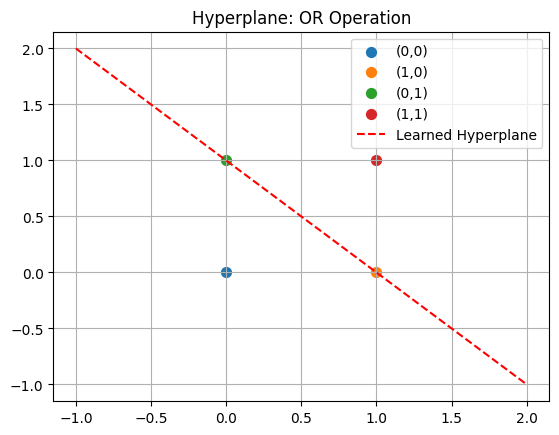

In [20]:
# w[0] - bias
# w[1] - weight 1
# w[2] - weight 2

x_1 = np.linspace(-1, 2, 10)
x_2 = -(weights[1] / weights[2]) * x_1 - (weights[0] / weights[2])

for point in sample_space:
    plt.scatter(point[0], point[1], s=50, label=f"({point[0]},{point[1]})")

plt.title("Hyperplane: OR Operation")
plt.plot(x_1, x_2, linestyle='--', color="red", label="Learned Hyperplane")
plt.legend()
plt.grid()
plt.show()

We can see above, the hyperplane seperates the features with at least 1 value in the binary input from no 1 values. Its also important to note that $(0,1)$ and $(1,0)$ lie on the decision boundary.

With this visualization, we can see what cannot be learned by the perceptron. For example, suppose we want to learn to differentiate between binary inputs with the same value verse different values. $(1,1)$ and $(0,0)$ would be in class 1 and $(0,1)$ and $(1,0)$ would be in class 0. Without going through the process, there is no hyperplane that can be computed to seperate these classes.

Now that the fundamentals of the perceptron have been established, lets learn something more practical.

### Section 2: Learning to Classify Hand-Written Numbers

The example above was trivial. The section below applies the fundamentals of the perceptron to classify hand-written numbers. The dataset used is the MNIST handwritten dataset. The train set contains 60,000 samples and the test set contains 10,000 samples. The images are a matrix containing (28x28) pixels.

Dataset MNIST
    Number of datapoints: 60000
    Root location: ../data
    Split: Train
Dataset MNIST
    Number of datapoints: 10000
    Root location: ../data
    Split: Test


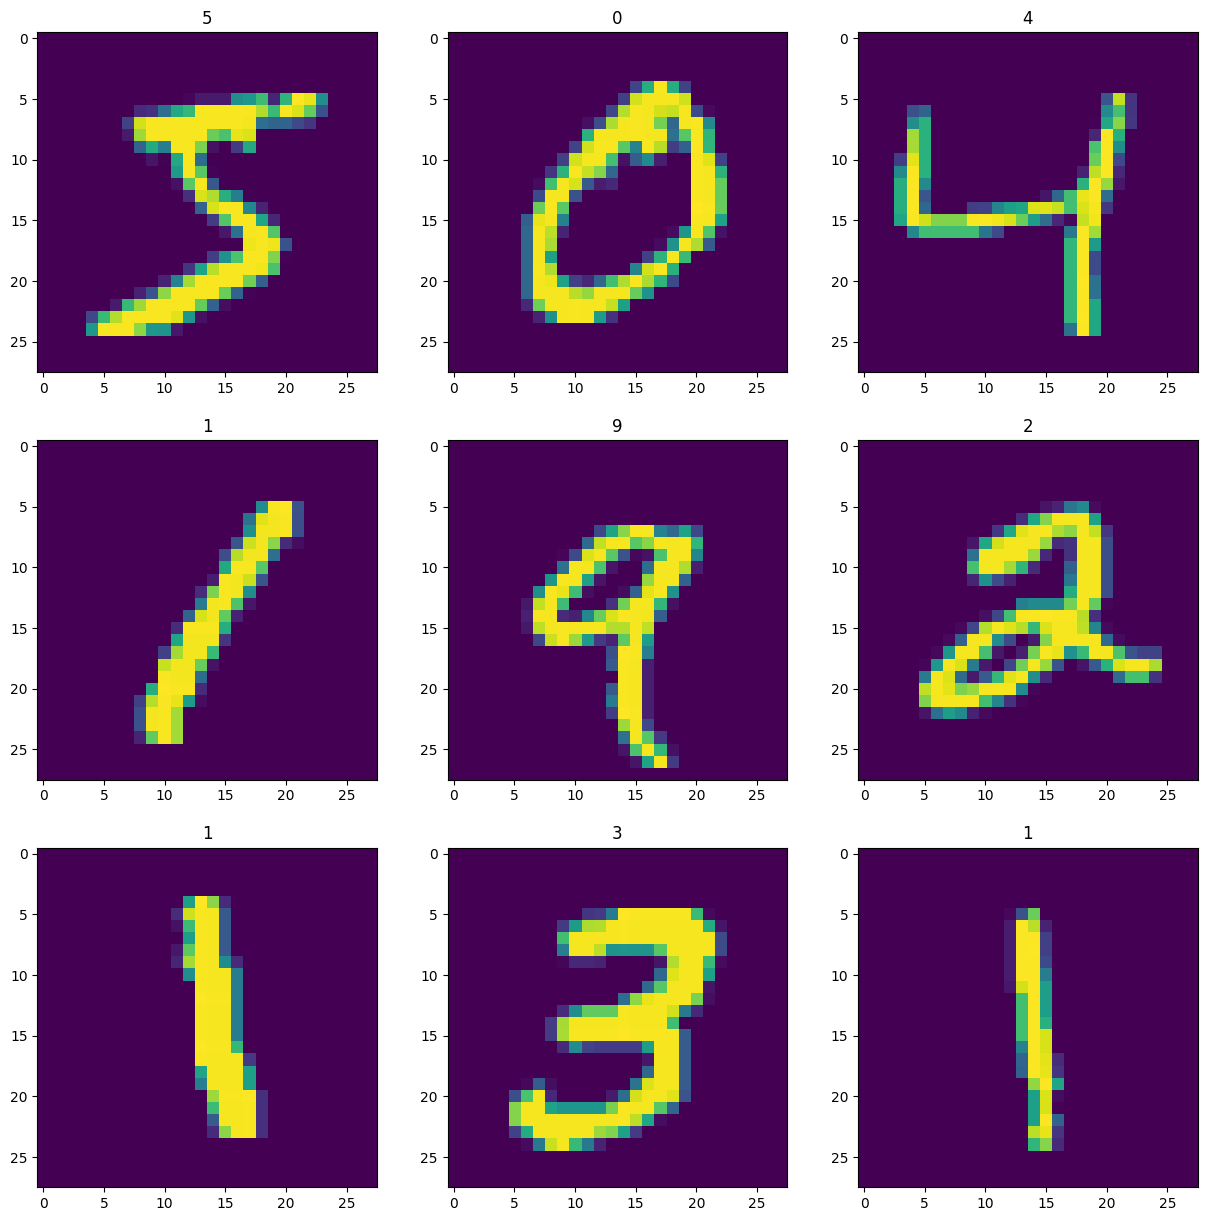

In [21]:
import torchvision

# Download the initial dataset
dataset = torchvision.datasets.MNIST(root="../data", download=True)

# Load the train and test data
train_set = torchvision.datasets.MNIST(root="../data", train=True)
test_set = torchvision.datasets.MNIST(root="../data", train=False)

figure_shape = (3, 3)
figure_idx = 0
fig, axes = plt.subplots(figure_shape[0], figure_shape[1], figsize=(15, 15))
for i in range(figure_shape[0]):
    for j in range(figure_shape[1]):
        image, label = train_set[figure_idx]
        figure_idx += 1

        axes[i][j].imshow(image, cmap="viridis")
        axes[i][j].set_title(label)

print(train_set)
print(test_set)

In [22]:
# Extract the raw test and train features
train_images = train_set.data.numpy()
train_labels = train_set.targets.numpy()

test_images = test_set.data.numpy()
test_labels = test_set.targets.numpy()

print(np.shape(train_images))
print(np.shape(train_labels))

(60000, 28, 28)
(60000,)


In [23]:
# Add the bias term to the train and test features
shape_len = 28 * 28
train_bias_coef = np.ones((len(train_labels), 1))
train_samples = train_images.reshape(-1, shape_len)
train_features = np.hstack((train_samples, train_bias_coef))

test_bias_coef = np.ones((len(test_labels), 1))
test_samples = test_images.reshape(-1, shape_len)
test_features = np.hstack((test_samples, test_bias_coef))

print(np.shape(train_features))
print(np.shape(test_features))

(60000, 785)
(10000, 785)


In [24]:
class Perceptron:
    def __init__(self, E: int) -> None:
        self.E = E  # number of epochs

    def train(self, X_train, y_train) -> None:
        # Initialize the weights
        self.w = np.zeros(len(X_train[0]))

        train_len = len(X_train)
        for e in range(self.E):
            print(f"Training Epoch={e+1} | train steps={train_len}")

            # Run through entire test set for each epoch
            for i in range(len(X_train)):
                y_hat = np.dot(X_train[i], self.w)

                l = 0
                if y_hat < 0 and y_train[i] == 1:
                    l = 1
                elif  y_hat >= 0 and y_train[i] == 0:
                    l = -1
                self.w = self.w + l * X_train[i]

    def predict(self, X_test):
        return np.dot(X_test, self.w)

Because the perceptron is a binary classifier, we need to specify what number we want to learn compared to the population. For example, if we want to learn the number "5", we set all number "5" labels to 1 and the rest of the number labels to 0.

In [25]:
# We want to learn to classify the number "5"
NUMBER = 5

X_train = train_features
y_train = np.where(train_labels == NUMBER, 1, 0)

perceptron = Perceptron(E=10)
perceptron.train(X_train, y_train)

# Test the model
X_test = test_features
y_test = np.where(test_labels == NUMBER, 1, 0)

# Test all samples in the test set and record the accuracy
results = 0
y_preds = []
for i in range(len(X_test)):
    linear_output = perceptron.predict(X_test[i])
    y_pred = 1 if linear_output >= 0 else 0
    y_preds.append(y_pred)
    results += int(y_pred == y_test[i])

accuracy = results / len(X_test)
print(f"Test Accuracy: {accuracy:.4%}")

Training Epoch=1 | train steps=60000
Training Epoch=2 | train steps=60000
Training Epoch=3 | train steps=60000
Training Epoch=4 | train steps=60000
Training Epoch=5 | train steps=60000
Training Epoch=6 | train steps=60000
Training Epoch=7 | train steps=60000
Training Epoch=8 | train steps=60000
Training Epoch=9 | train steps=60000
Training Epoch=10 | train steps=60000
Test Accuracy: 95.1100%


The test classification accuracy of $95\%$ is fairly good for our simple perceptron model. But what exactly did the model learn to classify the number "5"? To get some sense as to what the model learned, the section below investigates the perceptron's weights.

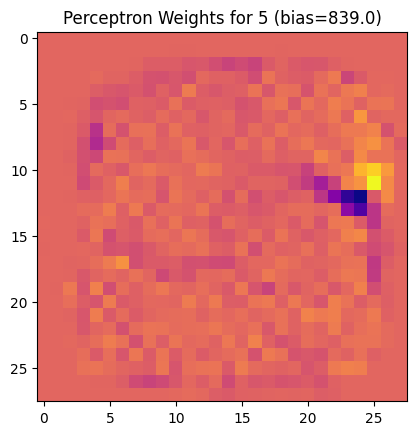

In [26]:
weights = perceptron.w
bias = weights[-1]
weights = weights[:-1]

weight_grid = weights.reshape((28,28))

plt.imshow(weight_grid, cmap="plasma")
plt.title(f"Perceptron Weights for 5 (bias={bias})")
plt.show()

This adds little information. Lets further inspect the classification performance.

In [27]:
from sklearn.metrics import classification_report, confusion_matrix

print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_preds)}")
print(f"Classification Report:\n{classification_report(y_test, y_preds)}")

Confusion Matrix:
[[9090   18]
 [ 471  421]]
Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      9108
           1       0.96      0.47      0.63       892

    accuracy                           0.95     10000
   macro avg       0.95      0.73      0.80     10000
weighted avg       0.95      0.95      0.94     10000



Lets investigate the classification performance further.

In the test set, there were 9108 class 0 (non-5) observations and 892 class 1 (5) observations. The test set is imbalanced, where only $8.92\%$ of the test observations are class 1. The perceptron learned how to successfully classify features that *are not* a 5. It correctly classifies close to $100\%$ of class 0 observations. On the other had, the perceptron struggles with classifying a $5$ (what the model was trained to do). It only correctly classifies $47\%$ of the class 1 test observations.

As we can see, the reported test accuracy of $95\%$ is misleading. One of the reasons for poor performance is the imbalanced data set. As we can see in the section below, only $9\%$ of the training data consists of class 1 (5). To fix this, let's oversample class 1 in the training data and retrain the perceptron. The training sample now has ~$40\%$ of class 1. Additionally, the number of training observations is increased to $200,000$,

In [28]:
pct_class_1_train = np.sum(y_train) / len(y_train)
print(f"Percent Class 1 in Training Data: {pct_class_1_train:.4%}")

Percent Class 1 in Training Data: 9.0350%


In [29]:
P = 0.40
N = 200_000

rng = np.random.default_rng()

# Oversample class 1
class_1_idxs = np.flatnonzero(train_labels == NUMBER)
class_0_idxs = np.flatnonzero(train_labels != NUMBER)

idxs = np.concatenate([
    rng.choice(class_1_idxs, size=int(N * P), replace=True),
    rng.choice(class_0_idxs, size=int(N * (1-P)), replace=True)
])
rng.shuffle(idxs)

X_train = train_features[idxs]
y_train = (train_labels[idxs] == NUMBER)

perceptron = Perceptron(E=10)
perceptron.train(X_train, y_train)

#  Re-test the model
X_test = test_features
y_test = np.where(test_labels == NUMBER, 1, 0)

# Test all samples in the test set and record the accuracy
results = 0
y_preds = []
for i in range(len(X_test)):
    linear_output = perceptron.predict(X_test[i])
    y_pred = 1 if linear_output >= 0 else 0
    y_preds.append(y_pred)
    results += int(y_pred == y_test[i])

accuracy = results / len(X_test)
print(f"Test Accuracy: {accuracy:.4%}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_preds)}")
print(f"Classification Report:\n{classification_report(y_test, y_preds)}")

Training Epoch=1 | train steps=200000
Training Epoch=2 | train steps=200000
Training Epoch=3 | train steps=200000
Training Epoch=4 | train steps=200000
Training Epoch=5 | train steps=200000
Training Epoch=6 | train steps=200000
Training Epoch=7 | train steps=200000
Training Epoch=8 | train steps=200000
Training Epoch=9 | train steps=200000
Training Epoch=10 | train steps=200000
Test Accuracy: 93.9000%
Confusion Matrix:
[[8587  521]
 [  89  803]]
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      9108
           1       0.61      0.90      0.72       892

    accuracy                           0.94     10000
   macro avg       0.80      0.92      0.85     10000
weighted avg       0.96      0.94      0.94     10000



This improved the model's performance! The model now predicts $94\%$ of class 0 test observations correctly and $90\%$ of class 1 test observations correctly. Now that we balanced the training dataset, we reached the limits of the perceptron's performance. To improve the class ification accuracy further, we need a multi-layer perceptron or a neural network.

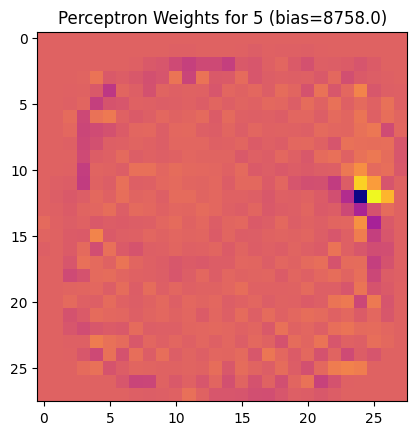

In [30]:
weights = perceptron.w
bias = weights[-1]
weights = weights[:-1]

weight_grid = weights.reshape((28,28))

plt.imshow(weight_grid, cmap="plasma")
plt.title(f"Perceptron Weights for 5 (bias={bias})")
plt.show()